<a href="https://colab.research.google.com/github/ApexShadow28/Machine-Learning/blob/main/HW6/faces_pca.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Dataset Loading and Dimensionality Inspection

### Overview & Operational Context
The Olivetti Faces dataset captures 400 standardized grayscale facial images across 40 distinct human subjects (10 images per subject). The images were collected under varying illumination angles, facial expressions (open/closed eyes, smiling/neutral), and facial accessories (glasses vs. no glasses). In its raw representation, each image is an uncompressed $64 \times 64$ matrix flattened into a 4,096-dimensional continuous feature vector with pixel intensities normalized between 0.0 and 1.0.

### Technical Implementation
1. We import the dataset directly via Scikit-Learn's built-in `fetch_olivetti_faces(shuffle=True, random_state=42)`.
2. We inspect and output the total number of image samples, unique subject classes, and raw feature dimensions.
3. We render a structured $4 \times 5$ subplot grid displaying 20 representative facial samples annotated with their respective subject class IDs (`target`).

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Total Image Samples: 400
Raw Feature Dimensions per Image: 4096 (64x64 pixels)
Unique Subject Identities: 40


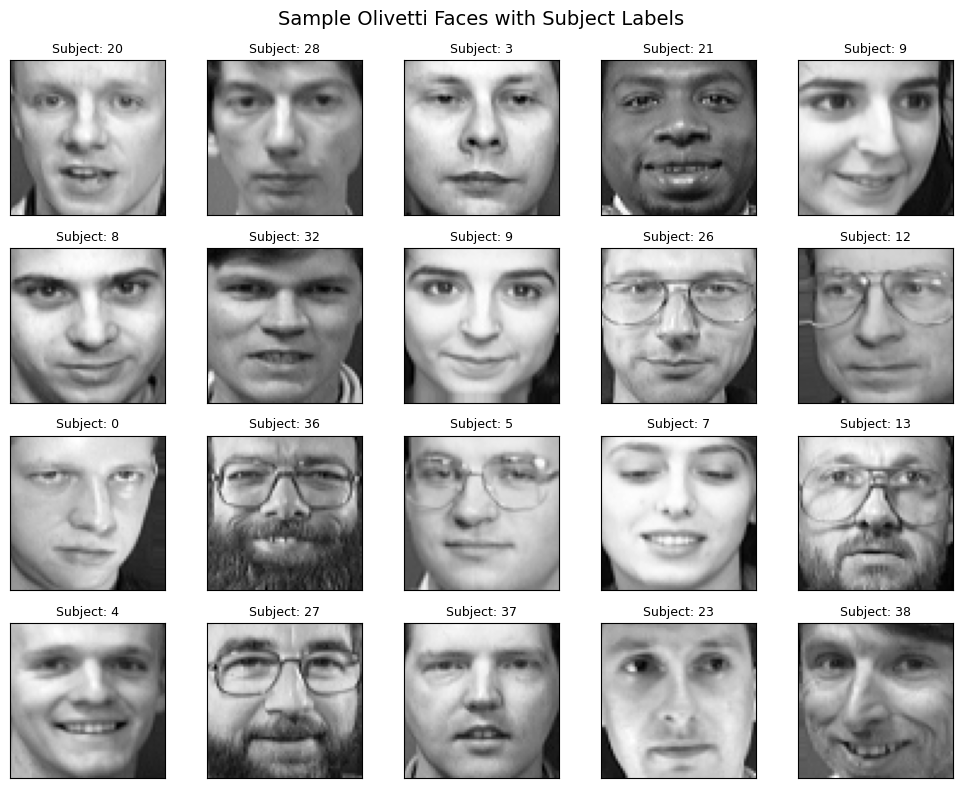

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_squared_error

# Load Olivetti Faces dataset
faces = fetch_olivetti_faces(shuffle=True, random_state=42)
X_raw = faces.data
y = faces.target
images = faces.images

n_samples, n_features = X_raw.shape
n_classes = len(np.unique(y))

print(f"Total Image Samples: {n_samples}")
print(f"Raw Feature Dimensions per Image: {n_features} (64x64 pixels)")
print(f"Unique Subject Identities: {n_classes}")

# Display a 4x5 grid of sample faces
fig, axes = plt.subplots(4, 5, figsize=(10, 8), subplot_kw={'xticks': [], 'yticks': []})
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap='gray')
    ax.set_title(f"Subject: {y[i]}", fontsize=9)
plt.suptitle("Sample Olivetti Faces with Subject Labels", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

# Task 2: Cumulative Explained Variance & Elbow Plot Analysis

### Overview & Operational Context
Principal Component Analysis (PCA) performs unsupervised linear transformation by projecting data onto orthogonal axes that maximize sample variance. Because high-dimensional image pixels share substantial spatial correlation, a small subset of principal components typically accounts for the majority of global image variance, allowing significant data compression without losing critical structural information.

### Technical Implementation
1. We fit a full PCA model (`n_components=n_samples`) on the dataset.
2. We compute both the individual explained variance ratio and cumulative explained variance curve across all principal components.
3. We determine the exact number of components required to capture 90%, 95%, and 99% of total cumulative variance.
4. We generate an annotated elbow plot displaying cumulative variance alongside threshold indicator lines.

Components required for 90% variance: 66 / 4096 (1.61%)
Components required for 95% variance: 123 / 4096 (3.00%)
Components required for 99% variance: 260 / 4096 (6.35%)


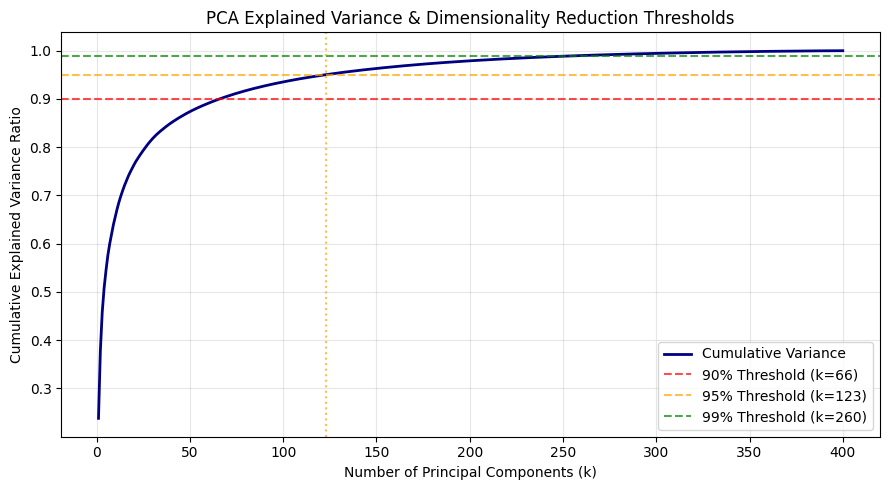

In [2]:
# Fit full PCA
pca_full = PCA(random_state=42)
pca_full.fit(X_raw)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Determine component thresholds
k_90 = np.argmax(cumulative_variance >= 0.90) + 1
k_95 = np.argmax(cumulative_variance >= 0.95) + 1
k_99 = np.argmax(cumulative_variance >= 0.99) + 1

print(f"Components required for 90% variance: {k_90} / {n_features} ({k_90/n_features*100:.2f}%)")
print(f"Components required for 95% variance: {k_95} / {n_features} ({k_95/n_features*100:.2f}%)")
print(f"Components required for 99% variance: {k_99} / {n_features} ({k_99/n_features*100:.2f}%)")

# Plot cumulative explained variance curve
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, color='navy', lw=2, label='Cumulative Variance')
plt.axhline(y=0.90, color='red', linestyle='--', alpha=0.7, label=f'90% Threshold (k={k_90})')
plt.axhline(y=0.95, color='orange', linestyle='--', alpha=0.7, label=f'95% Threshold (k={k_95})')
plt.axhline(y=0.99, color='green', linestyle='--', alpha=0.7, label=f'99% Threshold (k={k_99})')
plt.axvline(x=k_95, color='orange', linestyle=':', alpha=0.7)

plt.xlabel('Number of Principal Components (k)')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.title('PCA Explained Variance & Dimensionality Reduction Thresholds')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Task 3: Image Compression and Reconstruction Analysis

### Overview & Operational Context
Dimensionality reduction compresses data by projecting 4,096-dimensional vectors into a lower-dimensional $k$-dimensional latent space. Applying the inverse transform ($\mathbf{X}_{\text{reconstructed}} = \mathbf{X}_{\text{reduced}}\mathbf{W}^T + \boldsymbol{\mu}$) projects the compressed coordinates back into pixel space. Comparing the original image against its reconstruction illustrates how visual fidelity and high-frequency structural details improve as $k$ increases.

### Technical Implementation
1. We select 5 representative subject faces.
2. We compress and reconstruct these 5 faces using PCA across $k \in \{10, 50, 100, 200, 300\}$.
3. We plot a side-by-side comparison grid displaying the original faces alongside their reconstructed equivalents at each $k$.
4. We calculate and plot the Mean Squared Error (MSE) between original pixels and reconstructed pixels as a function of $k$.

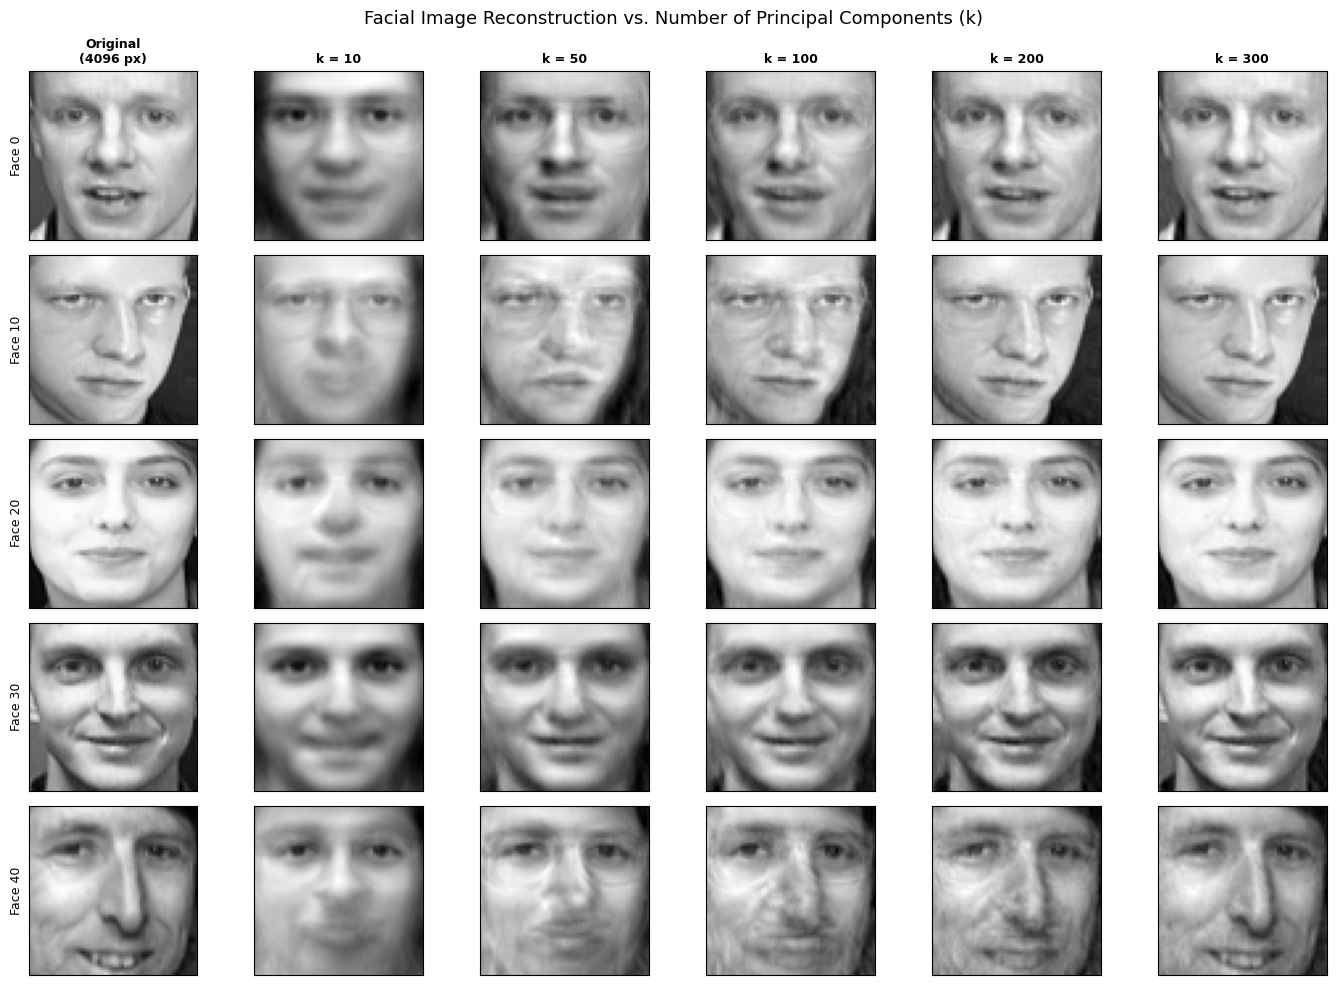

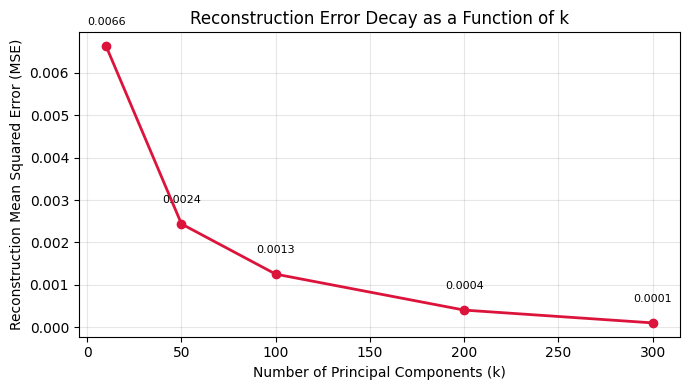

In [3]:
k_values = [10, 50, 100, 200, 300]
selected_indices = [0, 10, 20, 30, 40]
sample_images = X_raw[selected_indices]

# Image Reconstruction Grid
n_rows = len(selected_indices)
n_cols = len(k_values) + 1

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 10))

for r, idx in enumerate(selected_indices):
    # Original image
    axes[r, 0].imshow(X_raw[idx].reshape(64, 64), cmap='gray')
    if r == 0:
        axes[r, 0].set_title("Original\n(4096 px)", fontsize=9, fontweight='bold')
    axes[r, 0].set_ylabel(f"Face {idx}", fontsize=9)
    axes[r, 0].set_xticks([])
    axes[r, 0].set_yticks([])

    # Reconstructions across k
    for c, k in enumerate(k_values):
        pca_k = PCA(n_components=k, random_state=42).fit(X_raw)
        compressed = pca_k.transform(X_raw[idx:idx+1])
        reconstructed = pca_k.inverse_transform(compressed).reshape(64, 64)

        axes[r, c+1].imshow(reconstructed, cmap='gray')
        if r == 0:
            axes[r, c+1].set_title(f"k = {k}", fontsize=9, fontweight='bold')
        axes[r, c+1].set_xticks([])
        axes[r, c+1].set_yticks([])

plt.suptitle("Facial Image Reconstruction vs. Number of Principal Components (k)", fontsize=13, y=0.98)
plt.tight_layout()
plt.show()

# Mean Squared Error (MSE) curve across dataset
mse_scores = []
for k in k_values:
    pca_eval = PCA(n_components=k, random_state=42).fit(X_raw)
    X_recon = pca_eval.inverse_transform(pca_eval.transform(X_raw))
    mse = mean_squared_error(X_raw, X_recon)
    mse_scores.append(mse)

plt.figure(figsize=(7, 4))
plt.plot(k_values, mse_scores, marker='o', color='crimson', lw=2)
plt.xlabel('Number of Principal Components (k)')
plt.ylabel('Reconstruction Mean Squared Error (MSE)')
plt.title('Reconstruction Error Decay as a Function of k')
plt.grid(True, alpha=0.3)
for x, y_val in zip(k_values, mse_scores):
    plt.text(x, y_val + 0.0005, f"{y_val:.4f}", ha='center', fontsize=8)
plt.tight_layout()
plt.show()

# Task 4: Visualization of Principal Components ("Eigenfaces")

### Overview & Operational Context
The eigenvectors derived from the covariance matrix of facial images are termed "Eigenfaces." Each eigenvector is a 4,096-dimensional directional axis that can be reshaped back into a $64 \times 64$ matrix. Visualizing these components reveals the fundamental facial building blocks extracted by unsupervised variance maximization.

### Technical Implementation
1. We extract the first 15 principal components (`pca_full.components_[:15]`) from the fitted PCA model.
2. We reshape each eigenvector back into its native $64 \times 64$ image grid.
3. We render them in a $3 \times 5$ subplot grid, annotating each eigenface with its individual explained variance percentage.

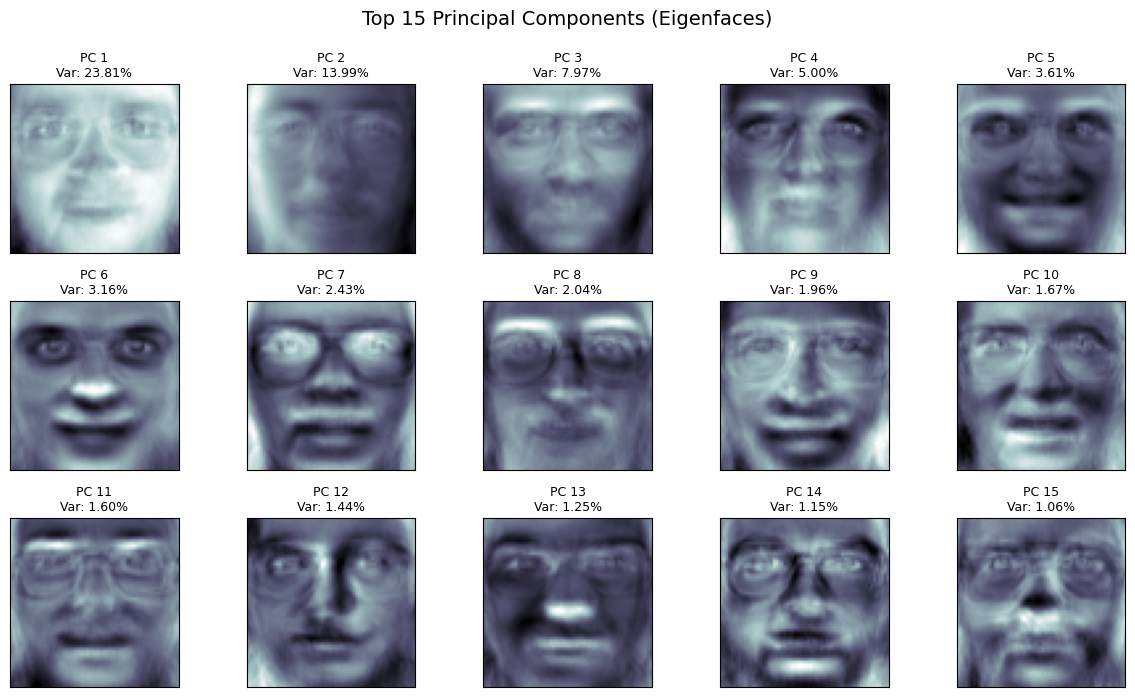

In [4]:
eigenfaces = pca_full.components_[:15]
explained_ratios = pca_full.explained_variance_ratio_[:15]

fig, axes = plt.subplots(3, 5, figsize=(12, 7), subplot_kw={'xticks': [], 'yticks': []})
for i, ax in enumerate(axes.flat):
    ax.imshow(eigenfaces[i].reshape(64, 64), cmap='bone')
    ax.set_title(f"PC {i+1}\nVar: {explained_ratios[i]*100:.2f}%", fontsize=9)

plt.suptitle("Top 15 Principal Components (Eigenfaces)", fontsize=14, y=0.99)
plt.tight_layout()
plt.show()

# Task 5: Linear Classification Baseline — Raw vs. PCA Features

### Overview & Operational Context
High-dimensional datasets frequently suffer from the curse of dimensionality, multicollinearity, and high training latency. By reducing features down to the 95% variance threshold ($k_{95}$), we evaluate whether dimensionality reduction accelerates training while preserving classification accuracy.

### Technical Implementation
1. We execute an 80/20 stratified split (`train_test_split(..., stratify=y, random_state=42)`).
2. To strictly prevent data leakage, we fit the PCA transformer containing the 95% variance threshold **exclusively on the training split** (`X_train`) and project both `X_train` and `X_test` into the reduced space.
3. We train two `LogisticRegression(max_iter=1000, random_state=42)` classifiers:
   - Model A: Trained on raw 4,096-dimensional features.
   - Model B: Trained on PCA-reduced features.
4. We record wall-clock training times, test accuracies, and render a dual-axis comparative bar plot.

Optimal components selected on train set (95% variance): 111 (compressed from 4096)
Raw Features  -> Accuracy: 0.9750 | Training Time: 15.2627s
PCA Features  -> Accuracy: 0.9750 | Training Time: 1.0196s


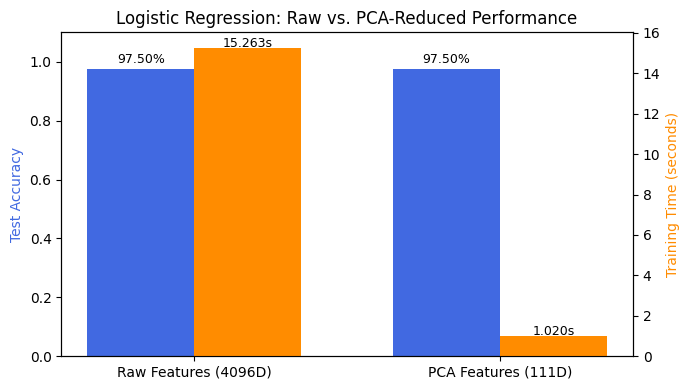

In [5]:
# 80/20 Stratified Split
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

# Fit PCA strictly on X_train to preserve 95% variance
pca_95 = PCA(n_components=0.95, random_state=42)
X_train_pca = pca_95.fit_transform(X_train_raw)
X_test_pca = pca_95.transform(X_test_raw)
k_selected = X_train_pca.shape[1]

print(f"Optimal components selected on train set (95% variance): {k_selected} (compressed from 4096)")

# Model 1: Logistic Regression on Raw Pixels
lr_raw = LogisticRegression(max_iter=1000, random_state=42)
t0 = time.time()
lr_raw.fit(X_train_raw, y_train)
t_lr_raw = time.time() - t0
acc_lr_raw = accuracy_score(y_test, lr_raw.predict(X_test_raw))

# Model 2: Logistic Regression on PCA Features
lr_pca = LogisticRegression(max_iter=1000, random_state=42)
t0 = time.time()
lr_pca.fit(X_train_pca, y_train)
t_lr_pca = time.time() - t0
acc_lr_pca = accuracy_score(y_test, lr_pca.predict(X_test_pca))

print(f"Raw Features  -> Accuracy: {acc_lr_raw:.4f} | Training Time: {t_lr_raw:.4f}s")
print(f"PCA Features  -> Accuracy: {acc_lr_pca:.4f} | Training Time: {t_lr_pca:.4f}s")

# Dual-Axis Comparison Plot
labels = ['Raw Features (4096D)', f'PCA Features ({k_selected}D)']
accuracies = [acc_lr_raw, acc_lr_pca]
times = [t_lr_raw, t_lr_pca]

x = np.arange(len(labels))
width = 0.35

fig, ax1 = plt.subplots(figsize=(7, 4))
ax2 = ax1.twinx()

rects1 = ax1.bar(x - width/2, accuracies, width, label='Accuracy', color='royalblue')
rects2 = ax2.bar(x + width/2, times, width, label='Training Time (s)', color='darkorange')

ax1.set_ylabel('Test Accuracy', color='royalblue')
ax2.set_ylabel('Training Time (seconds)', color='darkorange')
ax1.set_ylim(0, 1.1)
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
plt.title('Logistic Regression: Raw vs. PCA-Reduced Performance')

for r in rects1:
    ax1.text(r.get_x() + r.get_width()/2, r.get_height() + 0.02, f"{r.get_height():.2%}", ha='center', fontsize=9)
for r in rects2:
    ax2.text(r.get_x() + r.get_width()/2, r.get_height() + 0.05, f"{r.get_height():.3f}s", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# Task 6: Non-Linear Classification using Kernel SVM

### Overview & Operational Context
While linear classifiers construct planar decision boundaries, facial images often feature non-linear manifold structures caused by shadows, angle variations, and complex skin geometries. A Support Vector Classifier (SVC) equipped with a Radial Basis Function (`rbf`) kernel implicitly projects PCA features into a reproducing kernel Hilbert space to construct flexible non-linear decision boundaries.

### Technical Implementation
1. We train an `SVC(kernel='rbf', probability=True, random_state=42)` on `X_train_pca`.
2. We record training time and test accuracy on `X_test_pca`.
3. We plot a confusion matrix heatmap comparing predicted subject IDs against ground truth labels.

RBF Kernel SVM -> Accuracy: 0.9500 | Training Time: 0.1767s


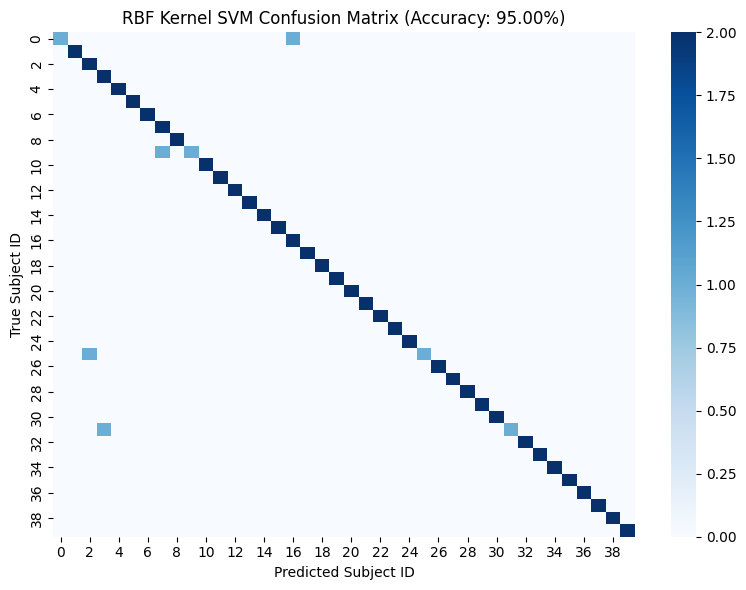

In [6]:
# Train RBF Kernel SVM
svc_rbf = SVC(kernel='rbf', probability=True, random_state=42)
t0 = time.time()
svc_rbf.fit(X_train_pca, y_train)
t_svc = time.time() - t0

y_pred_svc = svc_rbf.predict(X_test_pca)
acc_svc = accuracy_score(y_test, y_pred_svc)

print(f"RBF Kernel SVM -> Accuracy: {acc_svc:.4f} | Training Time: {t_svc:.4f}s")

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_svc)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, cmap='Blues', cbar=True, annot=False)
plt.xlabel('Predicted Subject ID')
plt.ylabel('True Subject ID')
plt.title(f'RBF Kernel SVM Confusion Matrix (Accuracy: {acc_svc:.2%})')
plt.tight_layout()
plt.show()

# Task 7: Ensemble Classification using Soft Voting

### Overview & Operational Context
Ensemble voting leverages model diversity by aggregating predictions across structurally heterogeneous algorithms. A soft voting ensemble averages class probability outputs, allowing models with higher confidence to outweigh ambiguous predictions.

### Technical Implementation
1. We instantiate three diverse classifiers:
   - Polynomial Kernel SVM (`SVC(kernel='poly', degree=2, probability=True, random_state=42)`)
   - RBF Kernel SVM (`SVC(kernel='rbf', probability=True, random_state=42)`)
   - Random Forest Classifier (`RandomForestClassifier(n_estimators=100, random_state=42)`)
2. We combine them into a `VotingClassifier(voting='soft')`.
3. We fit the ensemble on `X_train_pca`, measure execution latency, and calculate test accuracy on `X_test_pca`.

In [7]:
# Base models
clf_poly = SVC(kernel='poly', degree=2, probability=True, random_state=42)
clf_rbf = SVC(kernel='rbf', probability=True, random_state=42)
clf_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Soft Voting Ensemble
voting_clf = VotingClassifier(
    estimators=[('poly_svm', clf_poly), ('rbf_svm', clf_rbf), ('rf', clf_rf)],
    voting='soft'
)

t0 = time.time()
voting_clf.fit(X_train_pca, y_train)
t_ens = time.time() - t0

y_pred_ens = voting_clf.predict(X_test_pca)
acc_ens = accuracy_score(y_test, y_pred_ens)

print(f"Soft Voting Ensemble -> Accuracy: {acc_ens:.4f} | Training Time: {t_ens:.4f}s")
print("\nEnsemble Classification Report (Sample Summary):")
print(classification_report(y_test, y_pred_ens, zero_division=0))

Soft Voting Ensemble -> Accuracy: 0.9750 | Training Time: 0.6316s

Ensemble Classification Report (Sample Summary):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       

# Task 8: Comprehensive Comparative Model Evaluation

### Overview & Operational Context
To synthesize our findings, we compare the four tested model architectures across both predictive accuracy and training time efficiency:
1. Logistic Regression (Raw Features)
2. Logistic Regression (PCA-Reduced)
3. Support Vector Classifier with RBF Kernel (PCA-Reduced)
4. Soft Voting Ensemble (PCA-Reduced)

### Technical Implementation
We construct a unified dual-axis bar chart displaying test accuracy on the primary y-axis and wall-clock training time (in seconds) on the secondary y-axis across all four configurations.

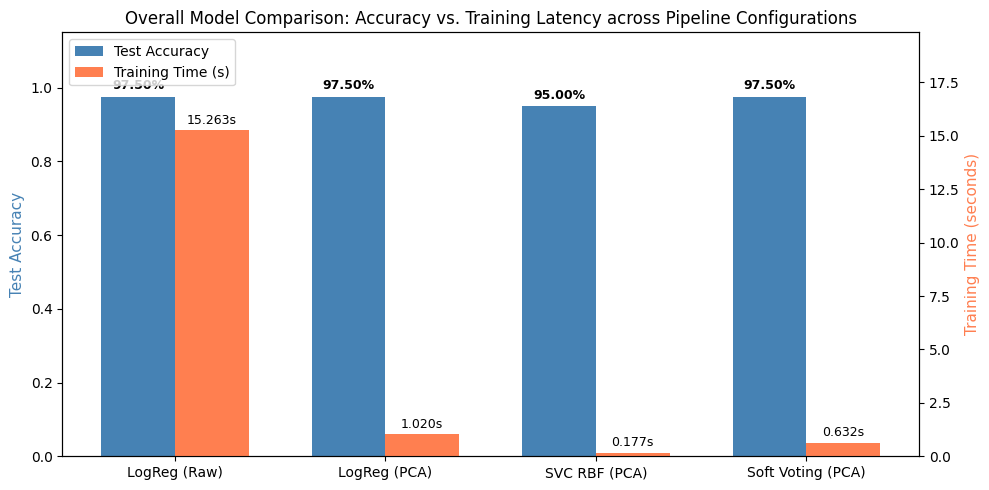

In [8]:
models = [
    'LogReg (Raw)',
    'LogReg (PCA)',
    'SVC RBF (PCA)',
    'Soft Voting (PCA)'
]
accuracies = [acc_lr_raw, acc_lr_pca, acc_svc, acc_ens]
training_times = [t_lr_raw, t_lr_pca, t_svc, t_ens]

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 5))
ax2 = ax1.twinx()

bars1 = ax1.bar(x - width/2, accuracies, width, label='Test Accuracy', color='steelblue')
bars2 = ax2.bar(x + width/2, training_times, width, label='Training Time (s)', color='coral')

ax1.set_ylabel('Test Accuracy', color='steelblue', fontsize=11)
ax2.set_ylabel('Training Time (seconds)', color='coral', fontsize=11)
ax1.set_ylim(0, 1.15)
ax2.set_ylim(0, max(training_times) * 1.3)
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Overall Model Comparison: Accuracy vs. Training Latency across Pipeline Configurations', fontsize=12)

# Value annotations
for b in bars1:
    ax1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02, f"{b.get_height():.2%}", ha='center', fontsize=9, fontweight='bold')
for b in bars2:
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + max(training_times)*0.02, f"{b.get_height():.3f}s", ha='center', fontsize=9)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()